# 04. 피처 엔지니어링 · 모델 · 튜닝 · 실험(E1~E5)

- 학습·튜닝·교차검증: 약한 라벨(D2, 날짜순 앞 80%), `TimeSeriesSplit`
- 약한 라벨 검증: D2 뒤 20%
- **최종 성능: 골드셋(D3에서 300건을 뽑아 AI(Claude)가 라벨링, 사람 검수 전)** — 검증 100건으로 임계값, 테스트 200건으로 평가

**임계값 결정**: 명세는 태그별로 골드 검증셋 F1이 최대인 값을 쓰라고 했지만, 검증셋 100건에서 태그당 양성이 0~14개뿐이다.
1차 실행에서 양성 2~4개 태그까지 개별 최적화하니 임계값이 0.95 같은 극단값으로 튀어 테스트 성능이 오히려 0.5 고정보다
낮았다(LR Micro F1 0.594 vs 0.604). 그래서 ① 검증셋에서 전 태그 공통 임계값을 Micro F1 기준으로 정하고
② 양성이 5개 이상인 태그만 개별 최적화한다(`evaluate.tune_thresholds`). 동점이면 높은 값(정밀도 우선).

두 점수의 차이가 "종목 기사에서 배운 것이 종목명 없는 일반 기사에 얼마나 통하는가"를 보여준다.

In [1]:
import sys, json, time
sys.path.insert(0, "..")
import warnings; warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
from joblib import parallel_config
from scipy import sparse
from scipy.stats import randint, uniform, loguniform
from sklearn.model_selection import GridSearchCV, RandomizedSearchCV, TimeSeriesSplit
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.multiclass import OneVsRestClassifier
from xgboost import XGBClassifier
from src.config import PROCESSED, GOLD, OUTPUTS, TAGS
from src.dataset import label_matrix, load_gold
from src.evaluate import KeywordRuleBaseline, multilabel_report, apply_thresholds, tune_thresholds, per_tag_report
from src.features import SEED_KEYWORDS, make_features
from src import features as F
from src.modeling import (as_frame, lr_pipeline, predict_proba, GoldEvaluator, FEAT_DEFAULT,
                          search_lr, search_rf, search_xgb, tree_features)
from src.text import tokenize_many
from src import viz
viz.setup()
# joblib은 큰 배열을 읽기 전용 메모리맵으로 워커에 넘기는데, liblinear가 여기에 쓰려다 크래시한다(Windows).
# 노트북 전체에서 메모리맵을 끈다.
parallel_config(max_nbytes=None).__enter__()
MODELS = OUTPUTS / "models"; MODELS.mkdir(exist_ok=True)
SEED = 42

train = pd.read_pickle(PROCESSED / "weak_train.pkl")
valid = pd.read_pickle(PROCESSED / "weak_valid.pkl")
d3 = pd.read_pickle(PROCESSED / "d3_clean.pkl")
Ytr, Yva = label_matrix(train.tag_list), label_matrix(valid.tag_list)

gold = load_gold()
gold["title_tokens"] = tokenize_many(gold.title_c.tolist())
gv, gt = gold[gold.split == "valid"].reset_index(drop=True), gold[gold.split == "test"].reset_index(drop=True)
Ygv, Ygt = label_matrix(gv.tag_list), label_matrix(gt.tag_list)
print(f"학습 {len(train):,} / 약한 검증 {len(valid):,} / 골드 검증 {len(gv)} · 테스트 {len(gt)}")
print(f"골드셋 '없음' 비율: {(label_matrix(gold.tag_list).sum(1) == 0).mean():.1%}")
pd.DataFrame({"weak_train": Ytr.sum(0), "gold_valid": Ygv.sum(0), "gold_test": Ygt.sum(0)}, index=TAGS).T

학습 28,738 / 약한 검증 7,185 / 골드 검증 100 · 테스트 200
골드셋 '없음' 비율: 60.7%


,반도체,2차전지,자동차,조선,철강·비철,원전·전력기기,방산,바이오·제약,인터넷·게임,금융(은행·증권·보험),건설·부동산,정유·화학,항공·여행,화장품·소비재,엔터·미디어
weak_train,2048,2168,1839,1840,2315,2171,2010,1863,1637,1867,1892,2412,2149,2221,2060
gold_valid,2,1,2,2,1,2,3,1,1,3,7,9,0,2,4
gold_test,8,2,4,0,5,7,3,2,3,12,14,9,7,4,4


In [2]:
Xtr, Xva = as_frame(train), as_frame(valid)
Xgv, Xgt = as_frame(gv), as_frame(gt)
ev = GoldEvaluator(Yva, Ygv, Ygt)

## 1. 도메인 키워드 사전 — "데이터로 후보를 뽑고 도메인 지식으로 거른다"
1) 태그별로 해당 태그 기사의 평균 TF-IDF − 나머지 기사 평균 TF-IDF가 큰 단어를 후보로 뽑는다.
2) 사람이 후보 중 **산업 고유 어휘**만 골라 시드 사전(`SEED_KEYWORDS`)에 추가한다.
   종목 기사 특유의 단어(주가, 목표가, 실적, 매수 등)와 남은 회사명은 일반 기사로 일반화되지 않으므로 뺀다.

In [3]:
tf = TfidfVectorizer(token_pattern=r"\S+", lowercase=False, min_df=5, max_features=30000, sublinear_tf=True)
T = tf.fit_transform(train.tokens)
vocab = np.array(tf.get_feature_names_out())
cand = {}
for j, tag in enumerate(TAGS):
    pos = Ytr[:, j] == 1
    diff = np.asarray(T[pos].mean(0) - T[~pos].mean(0)).ravel()
    cand[tag] = [w for w in vocab[np.argsort(-diff)[:40]] if w != "[기업]"][:30]
cand_df = pd.DataFrame({t: pd.Series(ws) for t, ws in cand.items()})
cand_df.head(30)

,반도체,2차전지,자동차,조선,철강·비철,원전·전력기기,방산,바이오·제약,인터넷·게임,금융(은행·증권·보험),건설·부동산,정유·화학,항공·여행,화장품·소비재,엔터·미디어
0,주가,배터리,타이어,운반선,철강,전력,방산,바이오,게임,금융,건설,화학,여행,뷰티,콘텐츠
1,상승,리튬,자동차,수주,리튬,주가,우주,치료제,신작,보험,주택,소재,노선,화장품,분기
2,반도체,LFP,부품,LNG,탄약,증권,항공,신약,사막,회장,수주,흑자,상품,브랜드,드라마
3,증권,전지,공장,조선,방산,종가,탄약,임상,MMORPG,은행,공사,분기,항공,K,IP
4,종가,합병,신차,상선,분기,장중,채용,의약품,모바일,후보,사업,석유,운항,글로벌,티빙
5,장중,양극,공급,선박,아르헨티나,상승,K,개발,업데이트,고객,구역,합병,프로모션,케어,아티스트
6,거래,철강,유럽,교섭,매각,하락,사업장,물질,출시,차기,정비,사업,관광,ODM,K
7,기준,ESS,평택,하청,탄소,원전,무기,미국,붉다,추천,현장,영업,통합,제품,제작
8,장비,주가,차량,선주,회장,고압,무인,후보,이용자,연금,건축,ESG,항공사,연구,플랫폼
9,하락,공급,관리,농성,환경,거래,체계,FDA,IP,어음,시공,이익,부산,북미,엔터


In [4]:
# 후보 중 사람이 고른 단어 (위 표를 보고 확정). 기존 시드에 없는 산업 어휘만.
# 고른 결과는 `src/features.py`의 `SEED_ADDED`에 있다 (튜닝 스크립트와 노트북이 같은 사전을 쓰도록).
# 뺀 것: 주가·종가·장중·증권·코스닥(종목 기사 상투어), 인명(곽동신, 최윤범 …), 회사·브랜드 약칭, 지역명
pd.DataFrame({t: pd.Series(F.SEED_ADDED.get(t, [])) for t in TAGS}).fillna("")
seeds = F.seed_keywords()
json.dump(seeds, open(PROCESSED / "seed_keywords.json", "w", encoding="utf-8"), ensure_ascii=False, indent=1)
pd.Series({t: len(v) for t, v in seeds.items()}, name="시드 키워드 수").to_frame().T

,반도체,2차전지,자동차,조선,철강·비철,원전·전력기기,방산,바이오·제약,인터넷·게임,금융(은행·증권·보험),건설·부동산,정유·화학,항공·여행,화장품·소비재,엔터·미디어
시드 키워드 수,27,29,23,26,23,27,30,33,28,29,33,25,30,26,26


## 2. 베이스라인: 키워드 룰
시드 키워드가 N개 이상 나오면 태그 부여. N은 골드 검증셋으로 고른다.

In [5]:
rows = []
for n in (1, 2, 3):
    rule = KeywordRuleBaseline(seeds, n=n)
    rows.append({"N": n, **multilabel_report(Ygv, rule.predict(gv.tokens), prefix="gold_valid_")})
pd.DataFrame(rows)

,N,gold_valid_micro_f1,gold_valid_micro_precision,gold_valid_micro_recall,gold_valid_macro_f1,gold_valid_hamming_loss,gold_valid_none_accuracy
0,1,0.3958,0.2500,0.950,0.4247,0.0773,0.52
1,2,0.5739,0.4400,0.825,0.5542,0.0327,0.69
2,3,0.5287,0.4894,0.575,0.4100,0.0273,0.70


In [6]:
best_n = max(rows, key=lambda r: r["gold_valid_micro_f1"])["N"]
rule = KeywordRuleBaseline(seeds, n=best_n)
S_va, S_gt = rule.scores(valid.tokens), rule.scores(gt.tokens)
row = {"model": f"키워드 룰 (N={best_n})", "note": "학습 없음"}
row.update(multilabel_report(Yva, (S_va >= best_n).astype(int), S_va, prefix="weak_"))
row.update(multilabel_report(Ygt, (S_gt >= best_n).astype(int), S_gt, prefix="gold_"))
row.update(multilabel_report(Ygt, (S_gt >= best_n).astype(int), prefix="gold@0.5_"))
ev.rows.append(row)
ev.table().tail(1)

,model,note,weak_micro_f1,weak_macro_f1,gold_micro_f1,gold_macro_f1,gold_micro_precision,gold_micro_recall,gold_precision_at_1,gold_hamming_loss,gold_none_accuracy,gold@0.5_micro_f1
0,키워드 룰 (N=2),학습 없음,0.4996,0.4815,0.4924,0.4694,0.3611,0.7738,0.7595,0.0447,0.605,0.4924


## 3. Logistic Regression — GridSearchCV (TimeSeriesSplit 5)
피처(단어 TF-IDF + 문자 TF-IDF + 키워드 사전)와 분류기를 `Pipeline`으로 묶어 전처리 파라미터까지 같이 탐색한다.
탐색: `C` ∈ {0.1, 1, 10}, 규제 L1/L2, 단어 `ngram_range` ∈ {(1,1), (1,2)}. 기준: 약한 라벨 Micro F1.

In [7]:
# 탐색 결과는 outputs/models/lr_search.joblib에 캐시된다 (`python scripts/tune.py`가 진행 로그와 함께 미리 계산).
lr_search = search_lr(Xtr, Ytr, cache=MODELS / "lr_search.joblib")
print(f"best: {lr_search.best_params_}, CV micro F1 {lr_search.best_score_:.4f}")
cvres = pd.DataFrame(lr_search.cv_results_)
cvres["gap(train-cv)"] = cvres.mean_train_score - cvres.mean_test_score
cvres["fit_sec"] = cvres.mean_fit_time.round(1)
cvres.sort_values("rank_test_score")[["params", "mean_train_score", "mean_test_score", "std_test_score",
                                      "gap(train-cv)", "fit_sec"]]

best: {'clf__estimator__C': 10, 'clf__estimator__penalty': 'l2', 'features__word__ngram_range': (1, 2)}, CV micro F1 0.6887


,params,mean_train_score,mean_test_score,std_test_score,gap(train-cv),fit_sec
11,"{'clf__estimator__C': 10, 'clf__estimator__pen...",0.984434,0.688674,0.021066,0.295760,55.8
10,"{'clf__estimator__C': 10, 'clf__estimator__pen...",0.977180,0.684130,0.020420,0.293051,60.7
9,"{'clf__estimator__C': 10, 'clf__estimator__pen...",0.988539,0.672645,0.023506,0.315894,52.0
7,"{'clf__estimator__C': 1, 'clf__estimator__pena...",0.894692,0.662406,0.025130,0.232286,56.0
8,"{'clf__estimator__C': 10, 'clf__estimator__pen...",0.983992,0.659436,0.022497,0.324557,54.7
6,"{'clf__estimator__C': 1, 'clf__estimator__pena...",0.879258,0.657690,0.024574,0.221568,49.4
5,"{'clf__estimator__C': 1, 'clf__estimator__pena...",0.807042,0.628334,0.026969,0.178709,35.6
4,"{'clf__estimator__C': 1, 'clf__estimator__pena...",0.802377,0.623051,0.025988,0.179327,32.1
3,"{'clf__estimator__C': 0.1, 'clf__estimator__pe...",0.704110,0.582555,0.034491,0.121554,37.7
2,"{'clf__estimator__C': 0.1, 'clf__estimator__pe...",0.694309,0.582175,0.034751,0.112134,32.2


학습 점수와 CV 점수의 차이(gap)로 과적합을 본다. 규제가 약할수록(C가 클수록) 학습 점수는 1에 가까워지고 gap이 커진다.

In [8]:
lr_best = lr_search.best_estimator_
lr_best.named_steps["clf"].n_jobs = -1  # 예측 단계에서는 태그별 병렬
P_lr = {k: predict_proba(lr_best, X) for k, X in {"wv": Xva, "gv": Xgv, "gt": Xgt}.items()}
th_lr, _ = ev.evaluate("Logistic Regression", P_lr["wv"], P_lr["gv"], P_lr["gt"], note=str(lr_search.best_params_))
joblib.dump({"model": lr_best, "thresholds": th_lr, "tags": TAGS}, MODELS / "lr.joblib")
ev.table().tail(1)

,model,note,weak_micro_f1,weak_macro_f1,gold_micro_f1,gold_macro_f1,gold_micro_precision,gold_micro_recall,gold_precision_at_1,gold_hamming_loss,gold_none_accuracy,gold@0.5_micro_f1
1,Logistic Regression,"{'clf__estimator__C': 10, 'clf__estimator__pen...",0.7005,0.6914,0.6218,0.5071,0.5505,0.7143,0.8734,0.0243,0.71,0.595


## 4. RandomForest — TF-IDF → TruncatedSVD(300) → OneVsRest(RF), RandomizedSearchCV
RF는 고차원 희소 행렬에 약해 SVD로 300차원으로 줄인다. 계산량 때문에 피처 행렬과 SVD는 학습셋에 한 번 맞춰
고정하고, 탐색은 RF 하이퍼파라미터(`n_estimators`, `max_depth`, `min_samples_leaf`, `max_features`, `max_samples`)에
집중한다. 트리 모델은 적합 비용이 커서 TimeSeriesSplit(3), 12회(실행 시간 제약으로 30회에서 축소).
(1차 실행에서 표본 비율 0.8·학습 점수 계산까지 넣었더니 2시간이 넘어 탐색 공간을 줄였다 → `src/modeling.search_rf`)

In [9]:
tf_ = tree_features(Xtr, Ytr, lr_search.best_params_["features__word__ngram_range"], others=(Xva, Xgv, Xgt))
feat, svd, keep = tf_["feat"], tf_["svd"], tf_["keep"]
Ftr, Fva, Fgv, Fgt = tf_["F"]
Dtr, Dva, Dgv, Dgt = tf_["D"]
Str, Sva, Sgv, Sgt = tf_["S"]
print("피처 행렬:", Ftr.shape, "→ SVD", Dtr.shape, f"(설명 분산 {svd.explained_variance_ratio_.sum():.1%})",
      "| chi² 선택", Str.shape)

rf_search = search_rf(Dtr, Ytr, cache=MODELS / "rf_search.joblib")
print(f"best: {rf_search.best_params_}, CV micro F1 {rf_search.best_score_:.4f}")
rf_best = rf_search.best_estimator_
P_rf = {k: predict_proba(rf_best, X) for k, X in {"wv": Dva, "gv": Dgv, "gt": Dgt}.items()}
th_rf, _ = ev.evaluate("RandomForest", P_rf["wv"], P_rf["gv"], P_rf["gt"], note=str(rf_search.best_params_))
joblib.dump({"features": feat, "svd": svd, "model": rf_best, "thresholds": th_rf, "tags": TAGS}, MODELS / "rf.joblib")
rf_train_f1 = multilabel_report(Ytr, apply_thresholds(predict_proba(rf_best, Dtr), 0.5))["micro_f1"]
print(f"과적합 확인 — 학습 Micro F1 {rf_train_f1} vs 약한 검증 {ev.rows[-1]['weak_micro_f1']}")
ev.table().tail(1)

피처 행렬: (28738, 80015) → SVD (28738, 300) (설명 분산 58.6%) | chi² 선택 (28738, 3000)


best: {'estimator__max_depth': 40, 'estimator__max_features': 0.1, 'estimator__max_samples': 0.5, 'estimator__min_samples_leaf': 9, 'estimator__n_estimators': 120}, CV micro F1 0.5854


과적합 확인 — 학습 Micro F1 0.8529 vs 약한 검증 0.6136


,model,note,weak_micro_f1,weak_macro_f1,gold_micro_f1,gold_macro_f1,gold_micro_precision,gold_micro_recall,gold_precision_at_1,gold_hamming_loss,gold_none_accuracy,gold@0.5_micro_f1
2,RandomForest,"{'estimator__max_depth': 40, 'estimator__max_f...",0.6136,0.6004,0.4893,0.4233,0.3826,0.6786,0.7848,0.0397,0.545,0.4833


## 5. XGBoost — 희소 행렬 그대로, RandomizedSearchCV + early stopping
- 탐색: 전체 피처를 chi² 기준 상위 3천 개로 줄인 희소 행렬에서 `n_estimators`, `max_depth`, `learning_rate`,
  `min_child_weight`, `subsample`, `colsample_bytree`, `reg_lambda` (15회, TimeSeriesSplit(3); 실행 시간 제약으로 30회에서 축소)
- 최종 적합: 태그마다 약한 검증셋으로 **early stopping**(30라운드)을 걸어 트리 수를 정한다.
- 계산량: 2만 개 피처로는 OvR 한 번 적합에 약 8분이 걸려(시험 측정) 3천 개 + `max_bin=32`로 줄였다(약 30초).

In [10]:
xgb_search = search_xgb(Str, Ytr, cache=MODELS / "xgb_search.joblib")
print(f"best: {xgb_search.best_params_}, CV micro F1 {xgb_search.best_score_:.4f}")

best: {'estimator__colsample_bytree': np.float64(0.3290418060840997), 'estimator__learning_rate': np.float64(0.22044355215811345), 'estimator__max_depth': 6, 'estimator__min_child_weight': 3, 'estimator__n_estimators': 249, 'estimator__reg_lambda': np.float64(0.5920565099445673), 'estimator__subsample': np.float64(0.8887995089067299)}, CV micro F1 0.5822


In [11]:
best_xgb_params = {k.replace("estimator__", ""): v for k, v in xgb_search.best_params_.items()}
best_xgb_params["n_estimators"] = 1500  # 상한만 크게 두고 early stopping으로 결정
xgb_models, best_iters = [], []
for j in range(len(TAGS)):
    spw = (1 - Ytr[:, j].mean()) / max(Ytr[:, j].mean(), 1e-6)
    m = XGBClassifier(tree_method="hist", max_bin=32, n_jobs=16, eval_metric="logloss", early_stopping_rounds=30,
                      scale_pos_weight=spw, random_state=SEED, **best_xgb_params)
    m.fit(Str, Ytr[:, j], eval_set=[(Sva, Yva[:, j])], verbose=False)
    xgb_models.append(m); best_iters.append(m.best_iteration)
print("태그별 early stopping 라운드:", dict(zip(TAGS, best_iters)))
xgb_proba = lambda S: np.column_stack([m.predict_proba(S)[:, 1] for m in xgb_models])
P_xgb = {"wv": xgb_proba(Sva), "gv": xgb_proba(Sgv), "gt": xgb_proba(Sgt)}
th_xgb, _ = ev.evaluate("XGBoost", P_xgb["wv"], P_xgb["gv"], P_xgb["gt"], note=str(xgb_search.best_params_))
joblib.dump({"features": feat, "keep": keep, "models": xgb_models, "thresholds": th_xgb, "tags": TAGS},
            MODELS / "xgb.joblib")
xgb_train_f1 = multilabel_report(Ytr, apply_thresholds(xgb_proba(Str), 0.5))["micro_f1"]
print(f"과적합 확인 — 학습 Micro F1 {xgb_train_f1} vs 약한 검증 {ev.rows[-1]['weak_micro_f1']}")
ev.table().tail(1)

태그별 early stopping 라운드: {'반도체': 13, '2차전지': 31, '자동차': 13, '조선': 448, '철강·비철': 35, '원전·전력기기': 12, '방산': 33, '바이오·제약': 20, '인터넷·게임': 52, '금융(은행·증권·보험)': 4, '건설·부동산': 6, '정유·화학': 17, '항공·여행': 18, '화장품·소비재': 19, '엔터·미디어': 37}


과적합 확인 — 학습 Micro F1 0.6845 vs 약한 검증 0.5881


,model,note,weak_micro_f1,weak_macro_f1,gold_micro_f1,gold_macro_f1,gold_micro_precision,gold_micro_recall,gold_precision_at_1,gold_hamming_loss,gold_none_accuracy,gold@0.5_micro_f1
3,XGBoost,{'estimator__colsample_bytree': np.float64(0.3...,0.5881,0.575,0.5,0.4302,0.4091,0.6429,0.8228,0.036,0.595,0.4205


> 주의: XGBoost early stopping에 약한 검증셋을 썼으므로 XGBoost의 `weak_*` 점수는 약간 낙관적이다.
> 골드셋 점수는 영향을 받지 않는다.

## E1. 모델 비교 (골드 테스트셋 기준)

In [12]:
e1 = ev.table()
e1.to_csv(OUTPUTS / "e1_model_comparison.csv", index=False, encoding="utf-8-sig")
e1.drop(columns="note")

,model,weak_micro_f1,weak_macro_f1,gold_micro_f1,gold_macro_f1,gold_micro_precision,gold_micro_recall,gold_precision_at_1,gold_hamming_loss,gold_none_accuracy,gold@0.5_micro_f1
0,키워드 룰 (N=2),0.4996,0.4815,0.4924,0.4694,0.3611,0.7738,0.7595,0.0447,0.605,0.4924
1,Logistic Regression,0.7005,0.6914,0.6218,0.5071,0.5505,0.7143,0.8734,0.0243,0.710,0.5950
2,RandomForest,0.6136,0.6004,0.4893,0.4233,0.3826,0.6786,0.7848,0.0397,0.545,0.4833
3,XGBoost,0.5881,0.5750,0.5000,0.4302,0.4091,0.6429,0.8228,0.0360,0.595,0.4205


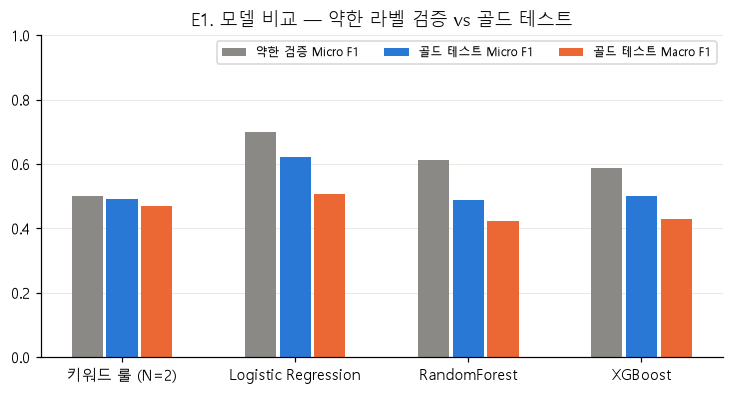

In [13]:
fig, ax = plt.subplots(figsize=(8, 3.8))
x = np.arange(len(e1)); w = 0.2
for k, (col, lab, c) in enumerate([("weak_micro_f1", "약한 검증 Micro F1", viz.GRAY),
                                   ("gold_micro_f1", "골드 테스트 Micro F1", viz.BLUE),
                                   ("gold_macro_f1", "골드 테스트 Macro F1", viz.ORANGE)]):
    ax.bar(x + (k - 1) * w, e1[col], w * 0.9, label=lab, color=c)
ax.set_xticks(x, e1.model); ax.set_ylim(0, 1); ax.legend(ncol=3, fontsize=8, loc="upper right")
ax.set_title("E1. 모델 비교 — 약한 라벨 검증 vs 골드 테스트"); ax.grid(axis="x", visible=False)
viz.save(fig, "e1_models"); plt.show()

**선정 기준**: 골드 테스트 Micro F1, 동점이면 정밀도가 높은 쪽 (알림 서비스는 엉뚱한 알림이 신뢰를 깎는다).

In [14]:
ml = e1[e1.model != e1.model.iloc[0]].sort_values(["gold_micro_f1", "gold_micro_precision"], ascending=False)
BEST = ml.model.iloc[0]
print("선정 모델:", BEST)
json.dump({"best_model": BEST}, open(MODELS / "best.json", "w", encoding="utf-8"), ensure_ascii=False)

선정 모델: Logistic Regression


## E2~E5. 무엇이 성능을 올렸나 (Logistic Regression으로 비교)
모든 실험은 3절에서 찾은 LR 하이퍼파라미터를 고정하고 입력·피처만 바꾼다.

In [15]:
bp = lr_search.best_params_
LR_KW = dict(C=bp["clf__estimator__C"], penalty=bp["clf__estimator__penalty"])
NGRAM = bp["features__word__ngram_range"]

def run_lr(name, Xtr_, Ytr_, Xva_, Yva_, Xgv_, Xgt_, feat_kw=None, note=""):
    kw = dict(FEAT_DEFAULT, word_ngram=NGRAM); kw.update(feat_kw or {})
    m = lr_pipeline(feature_kw=kw, **LR_KW).fit(Xtr_, Ytr_)
    e = GoldEvaluator(Yva_, Ygv, Ygt)
    _, row = e.evaluate(name, predict_proba(m, Xva_), predict_proba(m, Xgv_), predict_proba(m, Xgt_), note=note)
    return row, m

EXP_COLS = ["model", "weak_micro_f1", "weak_macro_f1", "gold_micro_f1", "gold_macro_f1", "gold_micro_precision",
            "gold_micro_recall", "gold_precision_at_1"]

### E2. 종목명 마스킹 O vs X
마스킹 X 모델은 원문(종목명 포함)으로 학습한다. 약한 검증셋도 원문이라 종목명만 외워도 점수가 높게 나온다.
골드셋(종목명 없는 기사)에서 얼마나 떨어지는지가 관심사다.

In [16]:
e2 = []
e2.append(run_lr("마스킹 O", Xtr, Ytr, Xva, Yva, Xgv, Xgt)[0])
Xtr_nm, Xva_nm = as_frame(train, "tokens_nomask", "text_raw"), as_frame(valid, "tokens_nomask", "text_raw")
row_nm, m_nm = run_lr("마스킹 X", Xtr_nm, Ytr, Xva_nm, Yva, Xgv, Xgt)
e2.append(row_nm)
# 마스킹 X 모델이 종목명에 의존하는 정도: 약한 검증셋을 '마스킹한 텍스트'로 바꿔 넣었을 때의 점수
row_x = multilabel_report(Yva, apply_thresholds(predict_proba(m_nm, Xva), 0.5), prefix="")
print(f"마스킹 X 모델에 마스킹된 약한 검증셋을 넣으면 Micro F1 {row_x['micro_f1']}")
e2 = pd.DataFrame(e2)[EXP_COLS]; e2

마스킹 X 모델에 마스킹된 약한 검증셋을 넣으면 Micro F1 0.4442


,model,weak_micro_f1,weak_macro_f1,gold_micro_f1,gold_macro_f1,gold_micro_precision,gold_micro_recall,gold_precision_at_1
0,마스킹 O,0.7005,0.6915,0.6218,0.5071,0.5505,0.7143,0.8734
1,마스킹 X,0.9333,0.9343,0.5843,0.4343,0.5532,0.6190,0.8608


In [17]:
coef = np.vstack([est.coef_.ravel() for est in m_nm.named_steps["clf"].estimators_])
names = m_nm.named_steps["features"].get_feature_names_out()
w_idx = np.where([n.startswith("word__") for n in names])[0]
top_nm = {t: [names[i].split("__", 1)[1] for i in w_idx[np.argsort(-coef[j, w_idx])[:8]]] for j, t in enumerate(TAGS)}
print("마스킹 X 모델의 태그별 상위 단어 피처 (종목명이 차지하는지 확인)")
pd.DataFrame(top_nm).T.head(8)

마스킹 X 모델의 태그별 상위 단어 피처 (종목명이 차지하는지 확인)


,0,1,2,3,4,5,6,7
반도체,ISC,한미반도체,테크윙,HPSP,리노공업,하나마이크론,엔지니어링,DB 하이텍
2차전지,엔켐,엘앤에프,SK이노베이션,에코프로,대주전자재료,포스코,포스코홀딩스,SK
자동차,화신,HL,한온시스템,기아차,현대위아,현대모비스,넥센타이어,에스엘
조선,현대힘스,한국 카본,카본,삼성중공업,동성화인텍,한화오션,세진중공업,한국
철강·비철,풍산,동국제강,고려아연,현대제철,포스코,포스코홀딩스,세아베스틸지주,POSCO
원전·전력기기,대한전선,한전,일진전기,우리기술,비에이치아이,두산에너빌리티,효성 중공업,효성
방산,풍산,빅텍,퍼스텍,현대로템,LIG,KAI,넥스원,LIG 넥스원
바이오·제약,에스티팜,종근당,HLB,한미약품,알테오젠,유한양행,리가켐바이오,대웅제약


### E3. 피처 조합

In [18]:
e3 = []
for name, kw in [("단어 TF-IDF", dict(word=True, char=False, keyword=False)),
                 ("문자 TF-IDF", dict(word=False, char=True, keyword=False)),
                 ("단어+문자", dict(word=True, char=True, keyword=False)),
                 ("단어+문자+키워드 사전", dict(word=True, char=True, keyword=True)),
                 ("단어+문자+키워드+메타(언론사·길이)", dict(word=True, char=True, keyword=True, meta=True))]:
    e3.append(run_lr(name, Xtr, Ytr, Xva, Yva, Xgv, Xgt, feat_kw=kw)[0])
e3 = pd.DataFrame(e3)[EXP_COLS]; e3

,model,weak_micro_f1,weak_macro_f1,gold_micro_f1,gold_macro_f1,gold_micro_precision,gold_micro_recall,gold_precision_at_1
0,단어 TF-IDF,0.6675,0.6585,0.5946,0.4710,0.5446,0.6548,0.8228
1,문자 TF-IDF,0.6721,0.6638,0.5537,0.3947,0.5269,0.5833,0.7975
2,단어+문자,0.6943,0.6862,0.6114,0.5027,0.5413,0.7024,0.7975
3,단어+문자+키워드 사전,0.7005,0.6915,0.6218,0.5071,0.5505,0.7143,0.8734
4,단어+문자+키워드+메타(언론사·길이),0.7023,0.6924,0.5752,0.4961,0.4577,0.7738,0.8481


### E4. 입력 길이: 제목만 vs 제목+요약
제목만 모델은 골드셋에도 제목만 넣는다 (같은 조건).

In [19]:
def title_frame(df, tok="tokens_title", txt="title_m"):
    return pd.DataFrame({"tokens": df[tok].values, "text": df[txt].values,
                         "press": df["press"].fillna("unknown").values, "log_len": np.log1p(df[txt].str.len()).values})
gv_t = gv.assign(tokens_title=gv.title_tokens, title_m=gv.title_c)
gt_t = gt.assign(tokens_title=gt.title_tokens, title_m=gt.title_c)
e4 = [run_lr("제목만", title_frame(train), Ytr, title_frame(valid), Yva, title_frame(gv_t), title_frame(gt_t))[0],
      run_lr("제목+요약", Xtr, Ytr, Xva, Yva, Xgv, Xgt)[0]]
e4 = pd.DataFrame(e4)[EXP_COLS]; e4

,model,weak_micro_f1,weak_macro_f1,gold_micro_f1,gold_macro_f1,gold_micro_precision,gold_micro_recall,gold_precision_at_1
0,제목만,0.5511,0.5415,0.5714,0.4791,0.5143,0.6429,0.7595
1,제목+요약,0.7005,0.6915,0.6218,0.5071,0.5505,0.7143,0.8734


### E5. 약한 라벨 제목 필터 O vs X
필터 X: 종목 검색 결과를 제목 확인 없이 모두 해당 종목 태그로 라벨링. 같은 태그별 상한을 적용해 규모를 맞췄다.
약한 검증셋은 각자 자기 규칙으로 만든 것이라 직접 비교가 어렵고, 골드셋 점수로 비교한다.

In [20]:
tr_nf = pd.read_pickle(PROCESSED / "weak_nofilter_train.pkl")
va_nf = pd.read_pickle(PROCESSED / "weak_nofilter_valid.pkl")
e5 = [run_lr("제목 필터 O", Xtr, Ytr, Xva, Yva, Xgv, Xgt)[0],
      run_lr("제목 필터 X", as_frame(tr_nf), label_matrix(tr_nf.tag_list), as_frame(va_nf),
             label_matrix(va_nf.tag_list), Xgv, Xgt)[0]]
e5 = pd.DataFrame(e5)[EXP_COLS]; e5

,model,weak_micro_f1,weak_macro_f1,gold_micro_f1,gold_macro_f1,gold_micro_precision,gold_micro_recall,gold_precision_at_1
0,제목 필터 O,0.7005,0.6915,0.6218,0.5071,0.5505,0.7143,0.8734
1,제목 필터 X,0.5596,0.5547,0.6292,0.5025,0.5957,0.6667,0.8101


In [21]:
exp = pd.concat({"E2 마스킹": e2, "E3 피처": e3, "E4 입력": e4, "E5 라벨필터": e5}).reset_index(level=0)
exp = exp.rename(columns={"level_0": "실험"})
exp.to_csv(OUTPUTS / "experiments_e2_e5.csv", index=False, encoding="utf-8-sig")
exp

,실험,model,weak_micro_f1,weak_macro_f1,gold_micro_f1,gold_macro_f1,gold_micro_precision,gold_micro_recall,gold_precision_at_1
0,E2 마스킹,마스킹 O,0.7005,0.6915,0.6218,0.5071,0.5505,0.7143,0.8734
1,E2 마스킹,마스킹 X,0.9333,0.9343,0.5843,0.4343,0.5532,0.6190,0.8608
0,E3 피처,단어 TF-IDF,0.6675,0.6585,0.5946,0.4710,0.5446,0.6548,0.8228
1,E3 피처,문자 TF-IDF,0.6721,0.6638,0.5537,0.3947,0.5269,0.5833,0.7975
2,E3 피처,단어+문자,0.6943,0.6862,0.6114,0.5027,0.5413,0.7024,0.7975
3,E3 피처,단어+문자+키워드 사전,0.7005,0.6915,0.6218,0.5071,0.5505,0.7143,0.8734
4,E3 피처,단어+문자+키워드+메타(언론사·길이),0.7023,0.6924,0.5752,0.4961,0.4577,0.7738,0.8481
0,E4 입력,제목만,0.5511,0.5415,0.5714,0.4791,0.5143,0.6429,0.7595
1,E4 입력,제목+요약,0.7005,0.6915,0.6218,0.5071,0.5505,0.7143,0.8734
0,E5 라벨필터,제목 필터 O,0.7005,0.6915,0.6218,0.5071,0.5505,0.7143,0.8734


## 6. 변수 중요도
- LR: 태그별 양(+)의 계수 상위 단어
- XGBoost: 태그별 gain 상위 피처

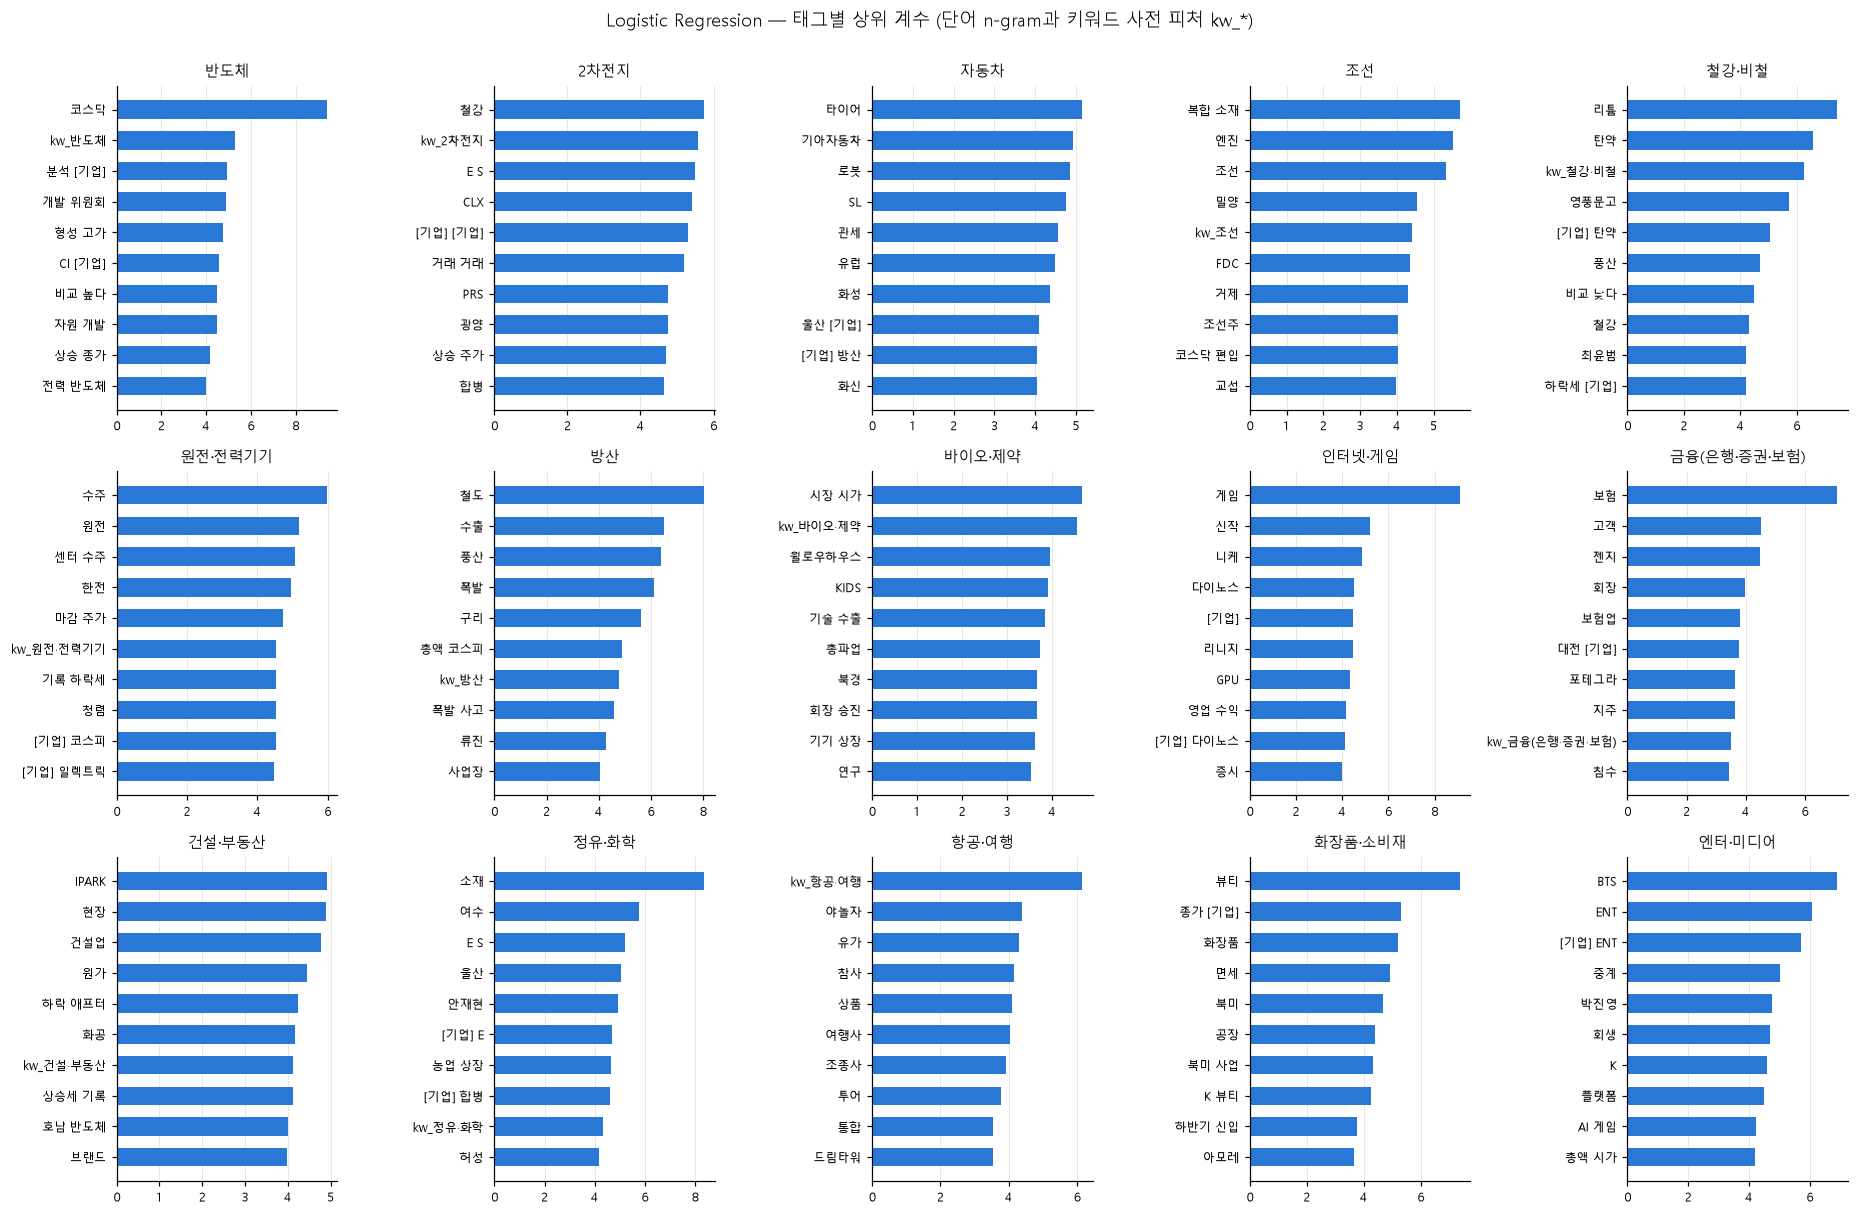

In [22]:
lr_names = lr_best.named_steps["features"].get_feature_names_out()
lr_coef = np.vstack([est.coef_.ravel() for est in lr_best.named_steps["clf"].estimators_])
fig, axes = plt.subplots(3, 5, figsize=(17, 11))
interp = np.array([n.startswith(("word__", "kw__")) for n in lr_names])  # 문자 n-gram은 조각이라 해석이 어려워 제외
for j, (tag, ax) in enumerate(zip(TAGS, axes.ravel())):
    idx = np.where(interp)[0][np.argsort(-lr_coef[j, interp])[:10]]
    labels = [n.split("__", 1)[1] for n in lr_names[idx]]
    ax.barh(labels[::-1], lr_coef[j, idx][::-1], color=viz.BLUE, height=0.6)
    ax.set_title(tag, fontsize=10); ax.tick_params(labelsize=8); ax.grid(axis="y", visible=False)
fig.suptitle("Logistic Regression — 태그별 상위 계수 (단어 n-gram과 키워드 사전 피처 kw_*)", y=1.0)
fig.tight_layout(); viz.save(fig, "lr_top_coef"); plt.show()

In [23]:
sel_names = feat.get_feature_names_out()[keep]
xgb_imp = {}
for tag, m in zip(TAGS, xgb_models):
    g = m.get_booster().get_score(importance_type="gain")
    top = sorted(g.items(), key=lambda kv: -kv[1])[:8]
    xgb_imp[tag] = [sel_names[int(k[1:])].replace("word__", "").replace("char__", "문자:").replace("kw__", "")
                    for k, _ in top]
pd.DataFrame({t: pd.Series(v) for t, v in xgb_imp.items()}).T

,0,1,2,3,4,5,6,7
반도체,문자:반도,문자:0원,반도체,문자:0원,문자:00원,kw_반도체,문자:스닥,문자:반도체
2차전지,문자: 양극,문자:차전지,문자:리튬,문자:차전,문자: 분리막,문자: e&,문자:00원,[기업] 울산
자동차,문자: 타이,kw_자동차,문자:신차,문자: 타이어,문자:자동차,문자:타이,문자:김승모,문자: 평택
조선,교섭,문자: 하청,문자: 노선,kw_조선,문자:00mw,kw_화장품·소비재,문자:반선,문자:도체
철강·비철,문자:철강,kw_철강·비철,문자: 철강,문자:리튬,철강,문자: 수주,문자:도체,문자:제철
원전·전력기기,문자: 초고,kw_원전·전력기기,문자:0원,문자:전력,기준,문자:초고압,원전,문자: 배전
방산,문자:우주,문자: 방산,문자: 무인,탄약,문자:대전사,문자:유도,문자: 무인기,방산
바이오·제약,문자:치료제,문자: 신약,ADC,문자:의약,문자:신약,문자:이오,문자:adc,임상
인터넷·게임,문자:신작,문자: 게,문자:게임,문자:이노스,문자:pg,MMORPG,"문자:',",신작
금융(은행·증권·보험),문자:금융,문자: 차기,문자:0원,kw_금융(은행·증권·보험),문자:후보,연금,문자:천위,기준 [기업]


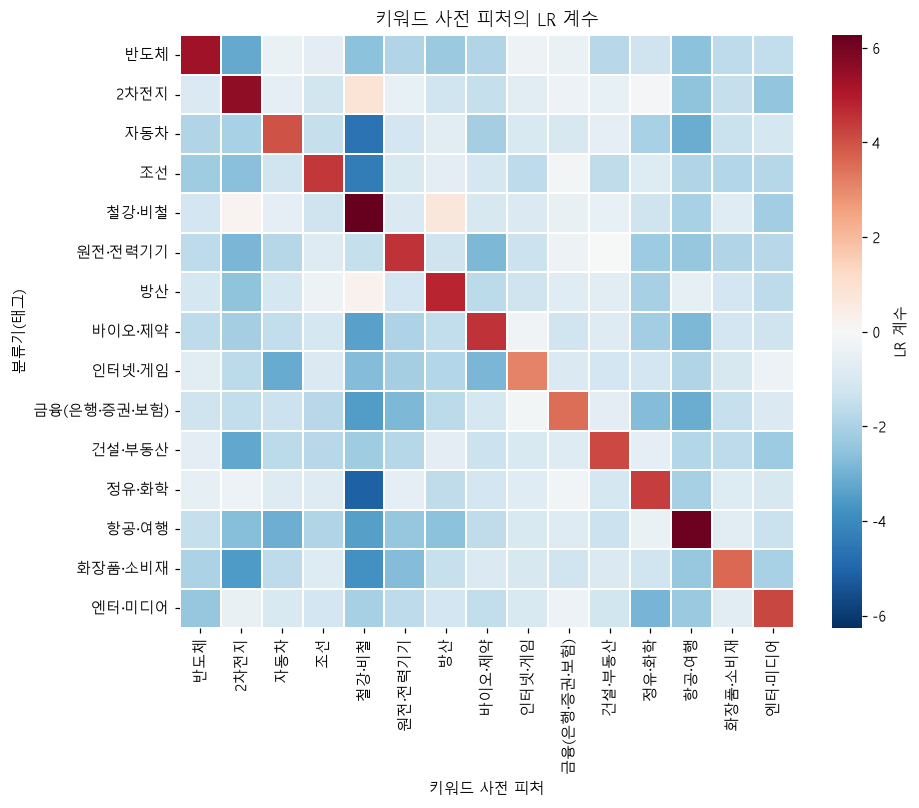

In [24]:
# 키워드 사전 피처(kw_*)가 각 태그 LR에서 갖는 계수: 자기 태그의 키워드 피처가 양(+)이면 사전이 일관되게 쓰인 것
kw_idx = [i for i, n in enumerate(lr_names) if n.startswith("kw__")]
kw_coef = pd.DataFrame(lr_coef[:, kw_idx], index=TAGS, columns=[lr_names[i].split("__kw_")[-1] for i in kw_idx])
fig, ax = plt.subplots(figsize=(9, 7))
import seaborn as sns
lim = np.abs(kw_coef.values).max()
sns.heatmap(kw_coef, cmap=viz.DIV, center=0, vmin=-lim, vmax=lim, ax=ax, linewidths=1, linecolor="white",
            cbar_kws={"label": "LR 계수"})
ax.set_xlabel("키워드 사전 피처"); ax.set_ylabel("분류기(태그)"); ax.set_title("키워드 사전 피처의 LR 계수")
viz.save(fig, "kw_coef_heatmap"); plt.show()

## 이 단계에서 알게 된 것

**E1 모델 비교** (골드 테스트 200건 / 약한 검증 7,185건)

| 모델 | 약한 검증 Micro F1 | 골드 Micro F1 | 골드 Macro F1 | 골드 정밀도 | 골드 재현율 | Precision@1 |
|---|---|---|---|---|---|---|
| 키워드 룰 (N=2) | 0.500 | 0.492 | 0.469 | 0.361 | **0.774** | 0.760 |
| **Logistic Regression** | **0.701** | **0.622** | **0.507** | **0.551** | 0.714 | **0.873** |
| RandomForest | 0.614 | 0.489 | 0.423 | 0.383 | 0.679 | 0.785 |
| XGBoost | 0.588 | 0.500 | 0.430 | 0.409 | 0.643 | 0.823 |

- **LR 선정**. 희소한 TF-IDF에서 선형 모델이 가장 강했다. RF는 SVD 300차원(설명 분산 59%)으로 줄이며 정보를 잃었고,
  XGBoost는 chi² 3천 개 피처와 early stopping(조선 448라운드를 빼면 4~52라운드)으로 일찍 멈췄다.
  CV 점수는 LR 0.689 > RF 0.585 ≈ XGB 0.582. RF·XGBoost는 실행 시간 제약으로 탐색을 12·15회로 줄여(1차 실행은 30회)
  CV 점수가 1차(0.592·0.605)보다 조금 낮지만, LR과의 차이(0.1 이상)에 비하면 작아 선정 결과는 같다.
- **약한 검증 → 골드 하락폭**: LR 0.701 → 0.622(−0.08). 종목 기사에서 배운 것이 일반 기사에도 상당 부분 통한다.
  키워드 룰은 두 점수가 거의 같다(0.50 / 0.49) — 사람이 만든 규칙은 도메인 차이의 영향을 덜 받는다.
- **과적합**: LR은 C가 클수록 학습 점수 0.98 대 CV 0.69로 차이가 커지지만, CV 점수도 C=10에서 가장 높았다.
  RF는 학습 0.85 vs 약한 검증 0.61, XGBoost는 0.68 vs 0.59.
- **임계값**: 1차 실행(태그별 개별 최적화)에서 LR 골드 F1이 0.594로 0.5 고정(0.604)보다 낮았다. 검증 100건으로는
  태그별 최적화가 과적합된다. 공통 임계값(이번 실행 0.8) + 양성 5개 이상 태그(건설·부동산 0.425, 정유·화학 0.95)만
  개별 조정으로 바꾸니 0.622로 0.5 고정(0.595)보다 높아졌다.

**E2~E5 (LR, 골드 테스트 Micro F1)** — 05에서 계산한 95% 구간이 약 ±0.08이라 0.03 미만 차이는 방향만 참고한다.

| 실험 | 비교 | 약한 검증 | 골드 Micro | 골드 Macro |
|---|---|---|---|---|
| E2 마스킹 | O / X | 0.701 / **0.933** | **0.622** / 0.584 | **0.507** / 0.434 |
| E3 피처 | 단어 / 문자 / 단어+문자 / +키워드 사전 / +메타 | 0.668 / 0.672 / 0.694 / 0.701 / 0.702 | 0.595 / 0.554 / 0.611 / **0.622** / 0.575 | 0.471 / 0.395 / 0.503 / **0.507** / 0.496 |
| E4 입력 | 제목만 / 제목+요약 | 0.551 / 0.701 | 0.571 / **0.622** | 0.479 / 0.507 |
| E5 라벨 필터 | 제목 필터 O / X | 0.701 / 0.560 | 0.622 / **0.629** | 0.507 / 0.503 |

- **E2**: 마스킹하지 않은 모델은 약한 검증에서 0.93을 찍지만, 상위 피처가 전부 종목명(ISC, 한미반도체, 풍산 …)이고
  종목명을 가린 검증셋에서는 0.44로 떨어진다. 골드셋에서는 Micro −0.04, Macro −0.07. **약한 검증 점수만 보면
  마스킹 없는 모델이 훨씬 좋아 보인다**는 점이 이 프로젝트의 방법론적 핵심이다.
- **E3**: 단어·문자 n-gram을 합치면 +0.02(0.595 → 0.611), 도메인 키워드 사전 15개 피처를 더하면 +0.01(0.622)로
  둘 다 같은 방향이지만 구간 안의 차이다. 언론사·길이 메타는 오히려 −0.05(정밀도 0.55 → 0.46): D2·D3 언론사 분포가 달라
  종목 기사 언론사에서 배운 편향이 일반 기사에 옮겨 가지 않는다.
- **E4**: 요약(본문 앞 1~2문장)을 넣으면 골드 +0.05, 약한 검증 +0.15. 제목만으로는 부족하다.
- **E5**: 제목 필터를 빼면 약한 검증은 크게 떨어지지만(라벨 노이즈), 골드는 오히려 +0.007(정밀도 0.55 → 0.60).
  '지나가는 언급' 기사에는 시황·업계 동향 기사가 많아 일반 경제 기사와 문체가 가깝기 때문으로 보인다.
  구간 안의 차이라 결론을 내리긴 어렵지만, **약한 라벨의 '정확도'와 '일반화'가 같은 방향이 아닐 수 있다**는 신호다.
- (시도했지만 효과 없음, 마스커 수정 전 실행) 주가·종가·목표가·숫자 같은 종목 기사 상투어를 지우고 학습: 골드 0.630 → 0.629.
- **변수 중요도**: LR 상위 피처는 산업 어휘의 문자 n-gram(반도·치료제·분양·노선·뷰티 등)과 키워드 사전 피처(kw_*)가
  대부분이지만, 경영자·창업자 이름(박진영·안와르 히즈아지·김범수의 '범수')과 브랜드명(메가박스)도 섞여 있다. 회사명을 가려도
  **인명·브랜드로 종목을 식별하는 길**이 남아 있다. 키워드 사전 피처는 15개 분류기 모두에서 자기 태그 피처의 계수가 양(+)이고
  15개 키워드 피처 중 가장 크다(3.1~6.3).